# RO membrane ML paper

Replicates Gao et al. (Materials 2025, 18, 840) on the Open Membrane Database. The paper reports 1,158 membrane IDs, 43 inputs, an 80/20 split, 5-fold CV, seven regressors, and validation R2 of 0.6469-0.6986. Exact code, seeds, hyperparameters, and a frozen data file were not published, so this notebook makes every reconstruction choice explicit.

Two evaluations are reported: (1) a paper-style random split for comparability and (2) a stricter publication-group split to detect leakage between membranes from the same source. The improved model uses a log1p target and tuned Extra Trees / CatBoost candidates.

In [22]:
!pip -q install catboost==1.2.8 xgboost==2.1.4 optuna==4.2.1
import json, hashlib, warnings, sys, platform
from datetime import datetime, timezone
from urllib.request import urlopen
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, KFold, GroupShuffleSplit, cross_validate
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, AdaBoostRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
import optuna
warnings.filterwarnings('ignore')
SEED=42
np.random.seed(SEED)
URL='https://raw.githubusercontent.com/Open-Membrane-Database/membranes/main/membranes.json'
raw=urlopen(URL).read()
print('UTC download:', datetime.now(timezone.utc).isoformat())
print('SHA256:', hashlib.sha256(raw).hexdigest(), 'bytes:', len(raw))
payload=json.loads(raw); records=payload['result']
print('records:', len(records), 'max OMD ID:', max(int(r['omdId']) for r in records))
print('Python:',sys.version.split()[0], 'platform:',platform.platform())

UTC download: 2026-11-07T05:44:51.552771+00:00
SHA256: 9fc4cbbbf090b67076624f26efcbe14e0b7d074d6237d4443d41922a57039daa bytes: 1129142
records: 1090 max OMD ID: 1158
Python: 3.13.18 platform: Linux-6.6.159+-x86_64-with-glibc2.39


In [23]:
# Reconstruct the paper's stated 43 inputs: membrane descriptors, filtration mode, CP and test conditions.
def vocab(field): return sorted({v for r in records for v in (r.get(field) or [])})
CHEM, STRUCT, MOD = vocab('chemistry'), vocab('structure'), vocab('modification')
FM=sorted({r.get('data',{}).get('filtrationMode','Not available') for r in records})
rows=[]
for r in records:
    d=r.get('data',{}); row={'omdId':int(r['omdId']), 'target_ab':d.get('ab'), 'cp':d.get('cp'), 'hydraulicP':d.get('hydraulicP'), 'naClConcM':d.get('naClConcM'), 'osmoticP':d.get('osmoticP'), 'group':r.get('report',{}).get('reference') or r.get('report',{}).get('_id') or r.get('_id')}
    for v in CHEM: row['chemistry__'+v]=int(v in (r.get('chemistry') or []))
    for v in STRUCT: row['structure__'+v]=int(v in (r.get('structure') or []))
    for v in MOD: row['modification__'+v]=int(v in (r.get('modification') or []))
    for v in FM: row['filtration__'+v]=int(d.get('filtrationMode','Not available')==v)
    rows.append(row)
df=pd.DataFrame(rows).replace([np.inf,-np.inf],np.nan).dropna(subset=['target_ab'])
numeric=['cp','hydraulicP','naClConcM','osmoticP']
for c in numeric: df[c]=df[c].fillna(df[c].mean())
feature_cols=[c for c in df if '__' in c]+numeric
X=df[feature_cols].astype(float); y=df.target_ab.astype(float); groups=df.group.astype(str)
print('shape:',X.shape, 'target range:',(y.min(),y.max()), 'target skew:',y.skew())
print({'chemistry':len(CHEM),'structure':len(STRUCT),'modification':len(MOD),'filtration':len(FM),'numeric':len(numeric)})

shape: (1090, 43) target range: (0.006969, 231.25000000000003) target skew: 4.750714082029837
{'chemistry': 21, 'structure': 5, 'modification': 10, 'filtration': 3, 'numeric': 4}


In [24]:
def metrics(y_true,pred):
    return {'R2':r2_score(y_true,pred),'MAE':mean_absolute_error(y_true,pred),'RMSE':mean_squared_error(y_true,pred)**0.5}
baseline_models={
 'MLP':make_pipeline(StandardScaler(),MLPRegressor(hidden_layer_sizes=(128,64),alpha=1e-3,max_iter=2000,early_stopping=True,random_state=SEED)),
 'kNN':make_pipeline(StandardScaler(),KNeighborsRegressor(n_neighbors=7,weights='distance')),
 'SVR':make_pipeline(StandardScaler(),SVR(C=10,epsilon=.1,gamma='scale')),
 'AdaBoost':AdaBoostRegressor(n_estimators=378,learning_rate=.03,loss='square',random_state=SEED),
 'CatBoost':CatBoostRegressor(iterations=700,depth=7,learning_rate=.035,l2_leaf_reg=5,loss_function='RMSE',verbose=False,random_seed=SEED),
 'XGBoost':XGBRegressor(n_estimators=700,max_depth=6,learning_rate=.035,subsample=.85,colsample_bytree=.85,reg_lambda=5,objective='reg:squarederror',random_state=SEED,n_jobs=-1),
 'Random Forest':RandomForestRegressor(n_estimators=700,min_samples_leaf=2,max_features=.8,n_jobs=-1,random_state=SEED)}
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.2,random_state=SEED)
paper_style=[]
for name,m in baseline_models.items():
    m.fit(Xtr,ytr); paper_style.append({'model':name,**metrics(yte,m.predict(Xte))})
paper_style=pd.DataFrame(paper_style).sort_values('R2',ascending=False)
display(paper_style.style.format({'R2':'{:.4f}','MAE':'{:.4f}','RMSE':'{:.4f}'}))

,model,R2,MAE,RMSE
6,Random Forest,0.8151,3.6507,7.0251
4,CatBoost,0.7941,4.0179,7.4145
5,XGBoost,0.7897,3.7795,7.4936
1,kNN,0.5902,5.6105,10.4598
0,MLP,0.5534,6.6076,10.9196
3,AdaBoost,0.4107,10.5498,12.5423
2,SVR,0.3052,6.7124,13.6191


In [25]:
# Fast, leakage-safe improvement stage.
cv = KFold(n_splits=3, shuffle=True, random_state=SEED)
candidate_models = {
    'ExtraTrees': ExtraTreesRegressor(
        n_estimators=600, min_samples_leaf=1, max_features=0.8,
        n_jobs=-1, random_state=SEED),
    'Log-ExtraTrees': TransformedTargetRegressor(
        regressor=ExtraTreesRegressor(
            n_estimators=600, min_samples_leaf=1, max_features=0.8,
            n_jobs=-1, random_state=SEED),
        func=np.log1p, inverse_func=np.expm1),
    'Log-CatBoost': TransformedTargetRegressor(
        regressor=CatBoostRegressor(
            iterations=500, depth=7, learning_rate=0.04, l2_leaf_reg=5,
            loss_function='RMSE', verbose=False, random_seed=SEED),
        func=np.log1p, inverse_func=np.expm1)
}

cv_rows = []
for name, model in candidate_models.items():
    scores = cross_validate(model, Xtr, ytr, cv=cv, scoring='r2', n_jobs=1)['test_score']
    cv_rows.append({'model': name, 'CV_R2_mean': scores.mean(), 'CV_R2_std': scores.std()})
cv_results = pd.DataFrame(cv_rows).sort_values('CV_R2_mean', ascending=False).reset_index(drop=True)

best_name = cv_results.loc[0, 'model']
winner2 = candidate_models[best_name]
winner2.fit(Xtr, ytr)
improved_results = pd.DataFrame([{'model': best_name, **metrics(yte, winner2.predict(Xte))}])

print('Training-only model selection:')
display(cv_results.style.format({'CV_R2_mean':'{:.4f}', 'CV_R2_std':'{:.4f}'}))
print('Untouched test-set result:')
display(improved_results.style.format({'R2':'{:.4f}', 'MAE':'{:.4f}', 'RMSE':'{:.4f}'}))

Training-only model selection:


,model,CV_R2_mean,CV_R2_std
0,Log-CatBoost,0.4676,0.1635
1,Log-ExtraTrees,0.4483,0.2408
2,ExtraTrees,0.4025,0.2742


Untouched test-set result:


,model,R2,MAE,RMSE
0,Log-CatBoost,0.7372,3.8239,8.3766


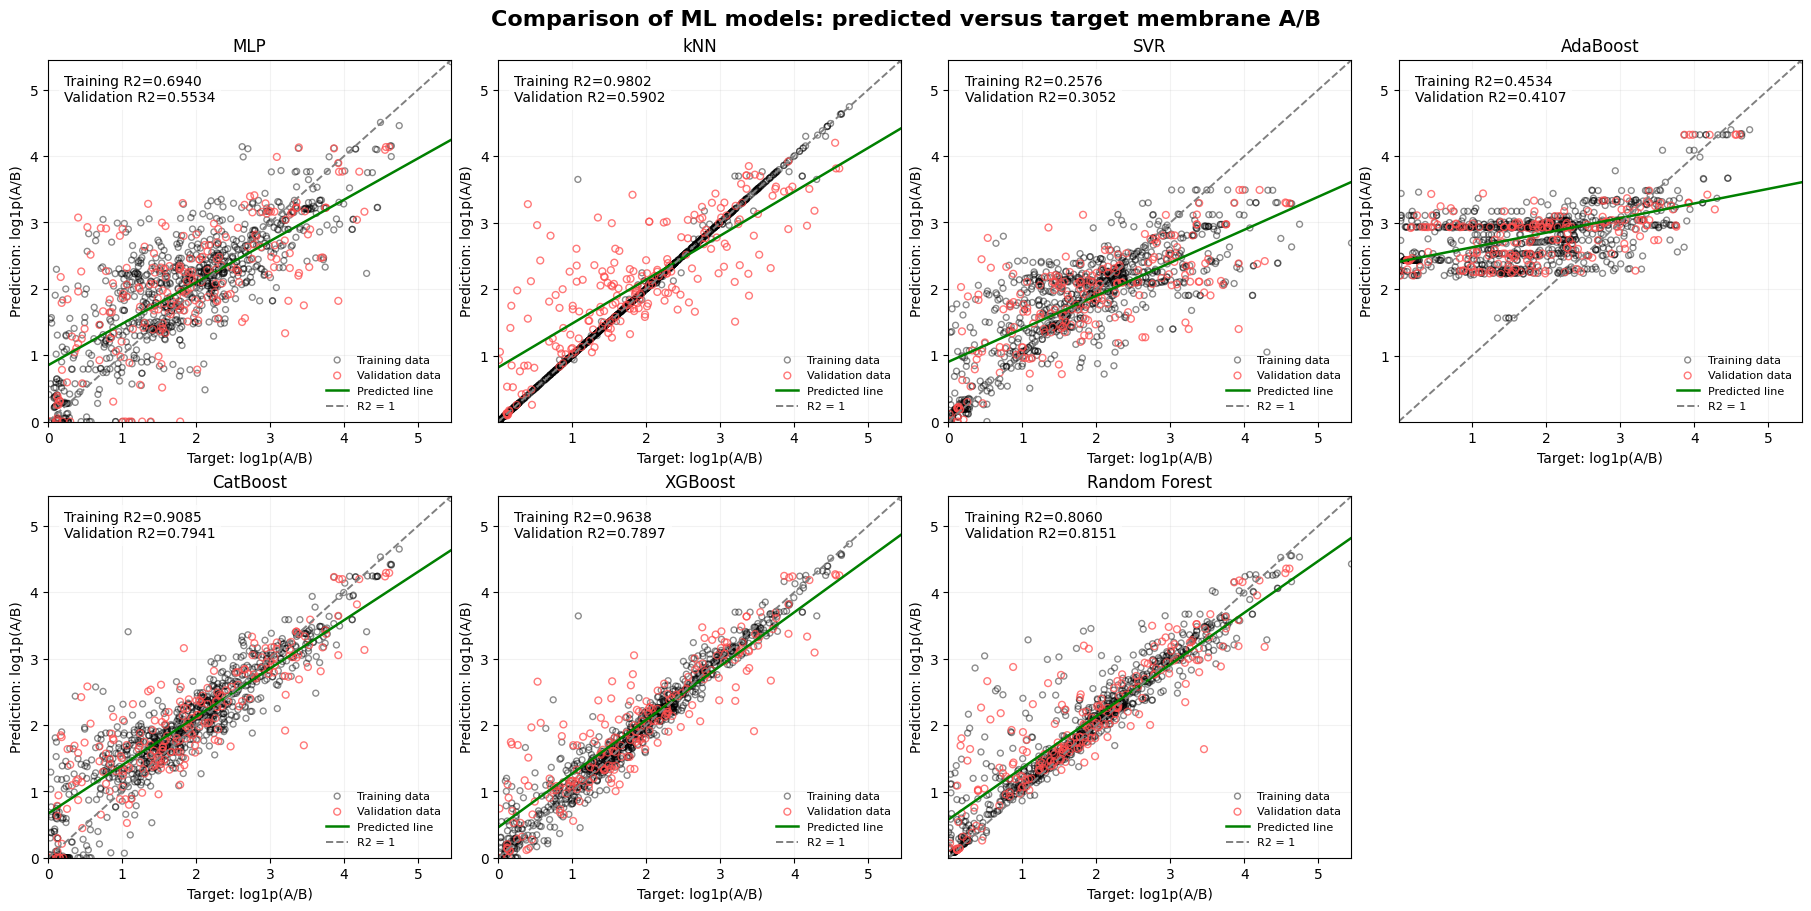

,Model,Training R2,Validation R2
6,Random Forest,0.8060,0.8151
4,CatBoost,0.9085,0.7941
5,XGBoost,0.9638,0.7897
1,kNN,0.9802,0.5902
0,MLP,0.6940,0.5534
3,AdaBoost,0.4534,0.4107
2,SVR,0.2576,0.3052


Saved high-resolution figure: /content/ml_model_comparison.png


In [26]:

comparison_rows = []
fig, axes = plt.subplots(2, 4, figsize=(18, 9), constrained_layout=True)
axes = axes.ravel()

for ax, (name, model) in zip(axes, baseline_models.items()):
    # Models were fitted in the benchmark cell; refit so this cell is also reproducible after edits.
    model.fit(Xtr, ytr)
    pred_train = model.predict(Xtr)
    pred_valid = model.predict(Xte)
    train_r2 = r2_score(ytr, pred_train)
    valid_r2 = r2_score(yte, pred_valid)
    comparison_rows.append({'Model': name, 'Training R2': train_r2, 'Validation R2': valid_r2})

    # log1p is used only for display because A/B is strongly right-skewed; R2 is computed on the original scale.
    x_train = np.log1p(ytr)
    y_train_plot = np.log1p(np.clip(pred_train, 0, None))
    x_valid = np.log1p(yte)
    y_valid_plot = np.log1p(np.clip(pred_valid, 0, None))

    ax.scatter(x_train, y_train_plot, s=18, facecolors='none', edgecolors='black', alpha=.45, label='Training data')
    ax.scatter(x_valid, y_valid_plot, s=24, facecolors='none', edgecolors='#ff4d4d', alpha=.75, label='Validation data')
    lo = min(x_train.min(), x_valid.min(), y_train_plot.min(), y_valid_plot.min())
    hi = max(x_train.max(), x_valid.max(), y_train_plot.max(), y_valid_plot.max())
    line_x = np.linspace(lo, hi, 200)
    slope, intercept = np.polyfit(x_valid, y_valid_plot, 1)
    ax.plot(line_x, slope * line_x + intercept, color='green', lw=1.8, label='Predicted line')
    ax.plot(line_x, line_x, '--', color='gray', lw=1.4, label='R2 = 1')
    ax.text(.04, .96, f'Training R2={train_r2:.4f}\nValidation R2={valid_r2:.4f}',
            transform=ax.transAxes, va='top', fontsize=10,
            bbox=dict(facecolor='white', alpha=.72, edgecolor='none'))
    ax.set(title=name, xlabel='Target: log1p(A/B)', ylabel='Prediction: log1p(A/B)')
    ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.grid(alpha=.16)
    ax.legend(loc='lower right', fontsize=8, frameon=False)

axes[-1].axis('off')
fig.suptitle('Comparison of ML models: predicted versus target membrane A/B', fontsize=16, fontweight='bold')
plt.savefig('/content/ml_model_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

comparison_metrics = pd.DataFrame(comparison_rows).sort_values('Validation R2', ascending=False)
display(comparison_metrics.style.format({'Training R2':'{:.4f}', 'Validation R2':'{:.4f}'}))
print('Saved high-resolution figure: /content/ml_model_comparison.png')

In [27]:
# Stricter audit
gss=GroupShuffleSplit(n_splits=1,test_size=.2,random_state=SEED)
gtr,gte=next(gss.split(X,y,groups))
group_model=RandomForestRegressor(n_estimators=1200,min_samples_leaf=2,max_features=.8,n_jobs=-1,random_state=SEED)
group_model.fit(X.iloc[gtr],y.iloc[gtr])
group_result=pd.DataFrame([{'model':'Random Forest (publication split)',**metrics(y.iloc[gte],group_model.predict(X.iloc[gte]))}])
display(group_result.style.format({'R2':'{:.4f}','MAE':'{:.4f}','RMSE':'{:.4f}'}))
print('Train/test publications:',groups.iloc[gtr].nunique(),groups.iloc[gte].nunique(),'overlap:',len(set(groups.iloc[gtr])&set(groups.iloc[gte])))

,model,R2,MAE,RMSE
0,Random Forest (publication split),0.6225,8.5130,14.1839


Train/test publications: 149 38 overlap: 0


Random Forest {'R2': 0.8151327261323089, 'MAE': 3.6506567698398475, 'RMSE': 7.025138515787344}


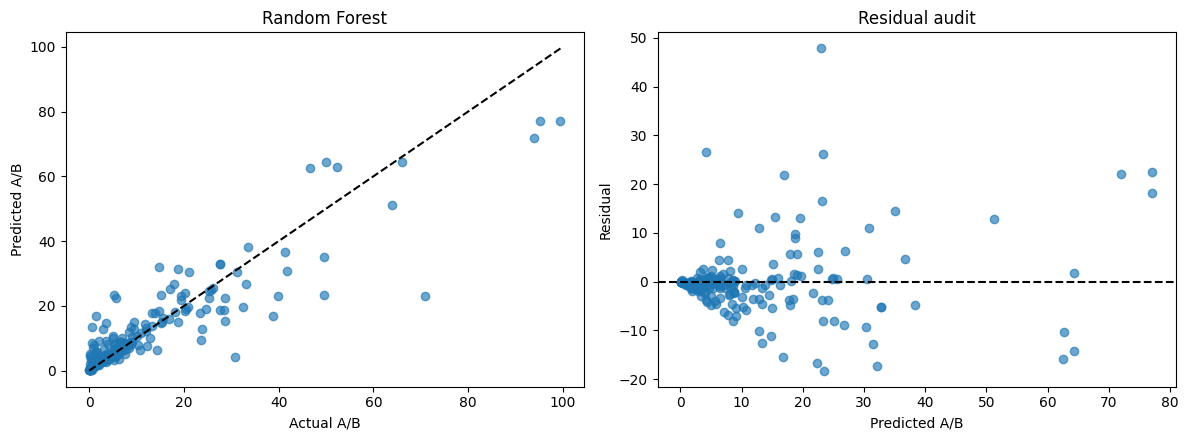

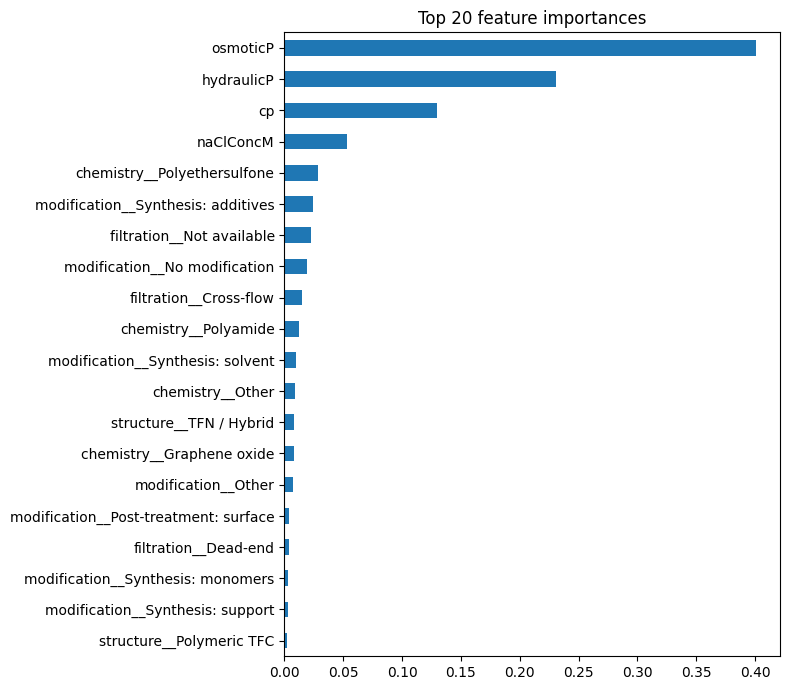

,importance
osmoticP,0.401055
hydraulicP,0.230704
cp,0.129952
naClConcM,0.053200
chemistry__Polyethersulfone,0.028924
modification__Synthesis: additives,0.024217
filtration__Not available,0.022335
modification__No modification,0.019334
filtration__Cross-flow,0.014733
chemistry__Polyamide,0.012429


In [28]:
# Diagnostics
winner_name='Random Forest'; winner=baseline_models[winner_name]
# The fitted estimator is already stored from the benchmark loop; refit explicitly for standalone execution.
winner.fit(Xtr,ytr)
pred=winner.predict(Xte)
print(winner_name, metrics(yte,pred))
fig,ax=plt.subplots(1,2,figsize=(12,4.5))
ax[0].scatter(yte,pred,alpha=.65); lim=[min(yte.min(),pred.min()),max(yte.max(),pred.max())]; ax[0].plot(lim,lim,'k--'); ax[0].set(xlabel='Actual A/B',ylabel='Predicted A/B',title=winner_name)
ax[1].scatter(pred,yte-pred,alpha=.65); ax[1].axhline(0,color='k',ls='--'); ax[1].set(xlabel='Predicted A/B',ylabel='Residual',title='Residual audit'); plt.tight_layout(); plt.show()
imp=pd.Series(winner.feature_importances_,index=feature_cols).sort_values(ascending=False).head(20)
imp.sort_values().plot.barh(figsize=(8,7),title='Top 20 feature importances'); plt.tight_layout(); plt.show(); display(imp.to_frame('importance'))